## Concrete Compressive Strength Prediction Using Machine Learning

1. Problem Statement and Project Objective

The objective of this project is to develop a machine learning regression model to predict the compressive strength of concrete based on its ingredients and curing age.

Concrete compressive strength is an important property used to evaluate the quality and durability of concrete. Predicting strength based on the quantities of different ingredients can help in understanding concrete performance and supporting construction material planning.

The project involves performing complete data analysis, building multiple regression models, comparing their performance, selecting the best-performing model, and predicting concrete strength for new input data.

## 1. Importing Required Libraries

The required Python libraries were imported to perform data manipulation, numerical computations, data visualization, preprocessing, machine learning model development, model evaluation, hyperparameter tuning, and model saving.

**Libraries Used:**

- **Pandas:** Used for loading, reading, manipulating, and analyzing the dataset.
- **NumPy:** Used for numerical calculations and mathematical operations.
- **Matplotlib:** Used for creating data visualizations such as histograms and scatter plots.
- **Seaborn:** Used for statistical visualizations such as boxplots and correlation heatmaps.
- **Warnings:** Used to control unnecessary warning messages during execution.
- **Scikit-learn:** Used for data splitting, feature scaling, regression algorithms, model evaluation, and hyperparameter tuning.
- **XGBoost:** Used to implement the XGBoost regression algorithm.
- **Pickle:** Used to save and load the trained machine learning model.

These libraries provided the necessary tools to complete the data analysis and machine learning workflow.

In [ ]:
# Importing required libraries for data manipulation, visualization, and modeling

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warning messages to keep the output clean
import warnings
warnings.filterwarnings('ignore')

# Machine learning utilities for preprocessing, model selection, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Linear Regression model and evaluation metrics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Dataset Description

The dataset contains 1,030 observations and 9 columns, including 8 quantitative input variables and 1 quantitative target variable.

Input Features:

Cement – Quantity of cement in the concrete mixture.

Blast Furnace Slag – Quantity of blast furnace slag.

Fly Ash – Quantity of fly ash.

Water – Quantity of water used in the mixture.

Superplasticizer – Quantity of superplasticizer.

Coarse Aggregate – Quantity of coarse aggregate.

Fine Aggregate – Quantity of fine aggregate.

Age – Curing age of concrete in days.

Target Variable:

Concrete Compressive Strength (MPa) – The measured compressive strength of concrete in Megapascals.

The dataset is used as a regression problem because the target variable is continuous numerical data.

## 3. Loading the Dataset

The concrete dataset is loaded using Pandas to perform data analysis and understand the different concrete ingredients and their relationship with compressive strength.

In [ ]:


# Load the concrete dataset from the CSV file
df = pd.read_csv("/content/concrete.csv")

# Display the first five records to preview features and values
df.head()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [ ]:
# Get the dimensions of the dataset (rows, columns)
df.shape

(1030, 9)

In [ ]:
# Verify the data types of each column in the DataFrame
df.dtypes

,0
cement,float64
slag,float64
ash,float64
water,float64
superplastic,float64
coarseagg,float64
fineagg,float64
age,int64
strength,float64


In [ ]:
# Print the names of all columns present in the dataset
df.columns

Index(['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg',
       'fineagg', 'age', 'strength'],
      dtype='object')

## 4. Data Understanding and Data Cleaning

Initially, the dataset was loaded using Pandas and inspected to understand its structure and characteristics.

The following activities were performed:

Checked dataset shape and column names.

Examined data types using dtypes and info().

Generated statistical summaries using describe().

Checked missing values using isnull().sum().

Identified duplicate records using duplicated().sum().



In [ ]:
# Display structural summary of the dataset including non-null counts and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cement        1030 non-null   float64
 1   slag          1030 non-null   float64
 2   ash           1030 non-null   float64
 3   water         1030 non-null   float64
 4   superplastic  1030 non-null   float64
 5   coarseagg     1030 non-null   float64
 6   fineagg       1030 non-null   float64
 7   age           1030 non-null   int64  
 8   strength      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [ ]:
# Generate a statistical summary (mean, std, min, max, percentiles) of the numerical features
df.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [ ]:
# Focus on the distribution statistics of the target variable (strength)
df['strength'].describe()

,strength
count,1030.000000
mean,35.817961
std,16.705742
min,2.330000
25%,23.710000
50%,34.445000
75%,46.135000
max,82.600000


In [ ]:
# Check for any missing values across all columns
df.isnull().sum()

,0
cement,0
slag,0
ash,0
water,0
superplastic,0
coarseagg,0
fineagg,0
age,0
strength,0


In [ ]:
# Count the total number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(25)

In [ ]:
# Retrieve and inspect the specific rows that are duplicates
df[df.duplicated()]

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
123,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29


In [ ]:
# Remove all duplicate records in-place to ensure clean training data
df.drop_duplicates(inplace=True)

# Confirm the new shape of the cleaned dataset
df.shape

(1005, 9)

In [ ]:
# Double-check that there are no remaining missing values post-cleaning
df.isnull().sum()

,0
cement,0
slag,0
ash,0
water,0
superplastic,0
coarseagg,0
fineagg,0
age,0
strength,0


## Observations:

Original dataset contained 1,030 rows and 9 columns.

No missing values were found.

25 duplicate records were identified.

Duplicate records were removed using drop_duplicates().

After removing duplicates, the dataset contained 1,005 observations and 9 columns.

# 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the distribution of the input variables and their relationships with concrete compressive strength.

The following techniques were used:

A. Univariate Analysis – Histograms

Histograms were plotted for all numerical features to understand their distributions.

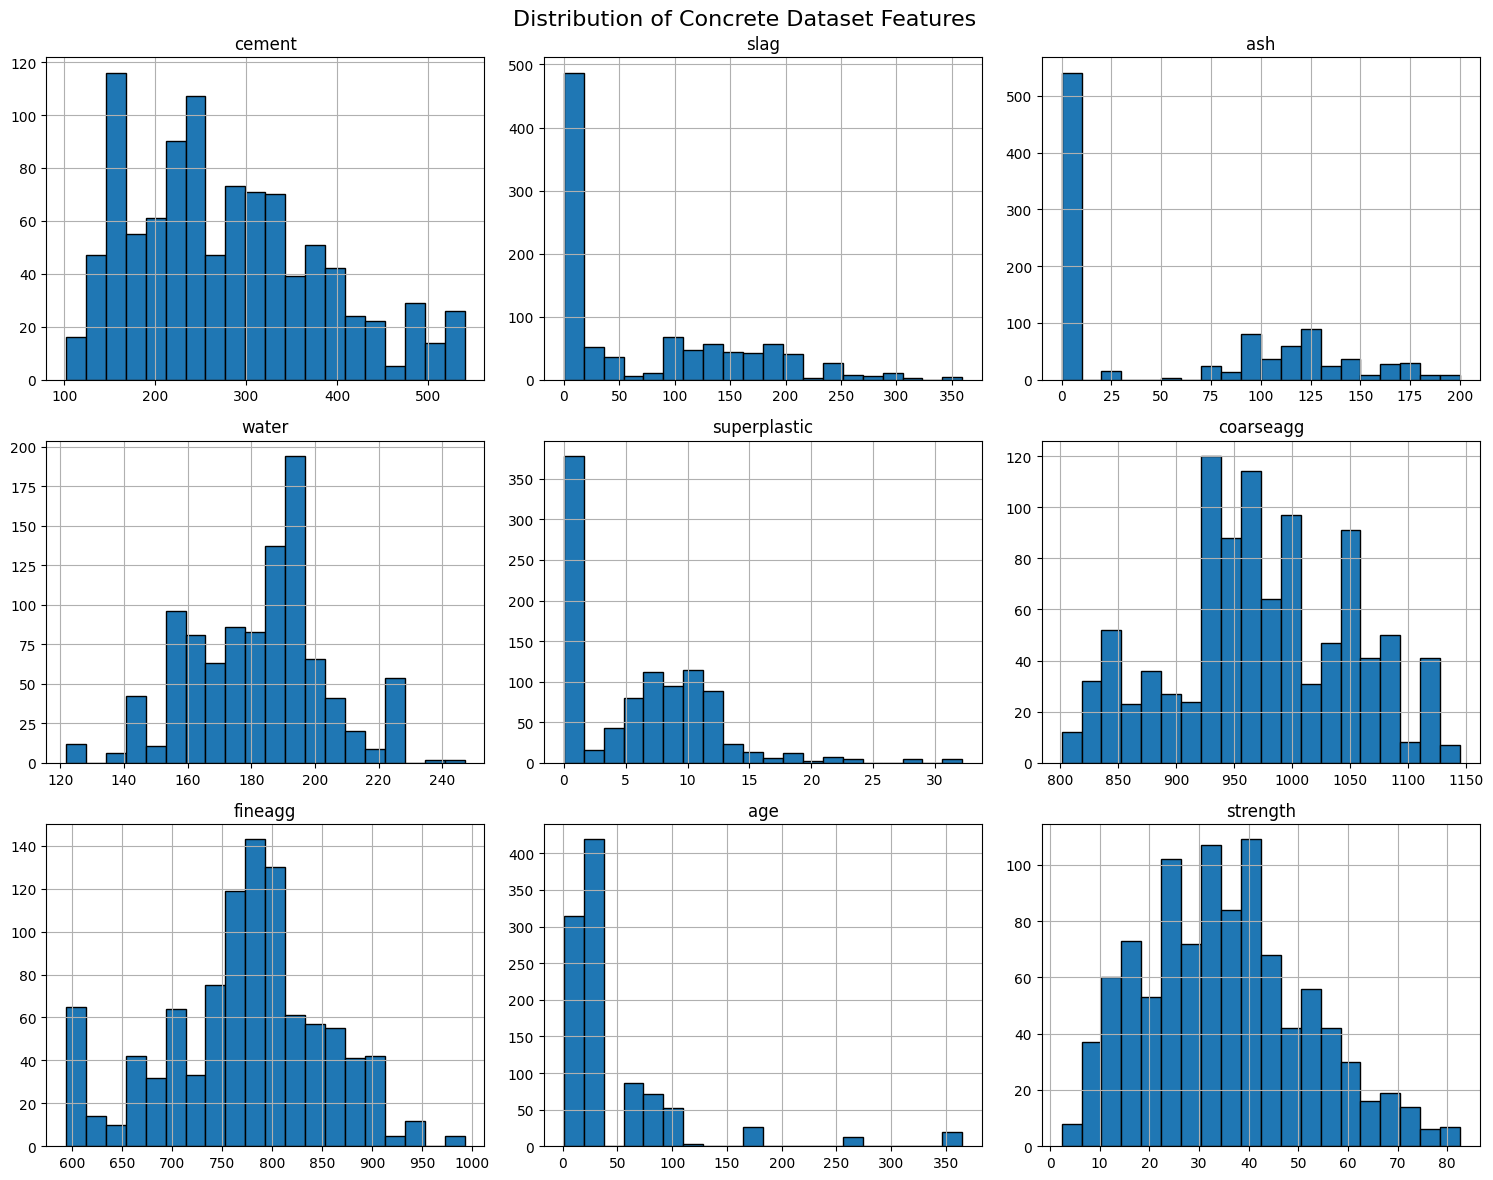

In [ ]:
# Plot individual histograms for all numeric features to observe distributions
df.hist(figsize=(15, 12), bins=20, edgecolor='black')

# Add a main title to the overall visualization layout
plt.suptitle("Distribution of Concrete Dataset Features", fontsize=16)

# Adjust spacing and display the final plots
plt.tight_layout()
plt.show()

## Observations:

Cement showed a broad distribution.

Slag and fly ash contained many zero values.

Superplasticizer also contained several zero values and showed a right-skewed distribution.

Age showed a highly right-skewed distribution.

Concrete strength values were distributed across a range of MPa values.

Zero values in slag, fly ash, and superplasticizer were treated as valid ingredient quantities rather than missing values.

## B. Outlier Analysis – Boxplots

Boxplots were created for all numerical columns to visually identify potential outliers.

The IQR (Interquartile Range) method was also applied to identify outliers statistically.

The detected outlier counts were:

Cement: 0

Slag: 2

Ash: 0

Water: 15

Superplasticizer: 10

Coarse Aggregate: 0

Fine Aggregate: 5

Age: 59

Strength: 8

Potential outliers were retained because they could represent genuine concrete measurements, such as different curing ages and concrete mix compositions.

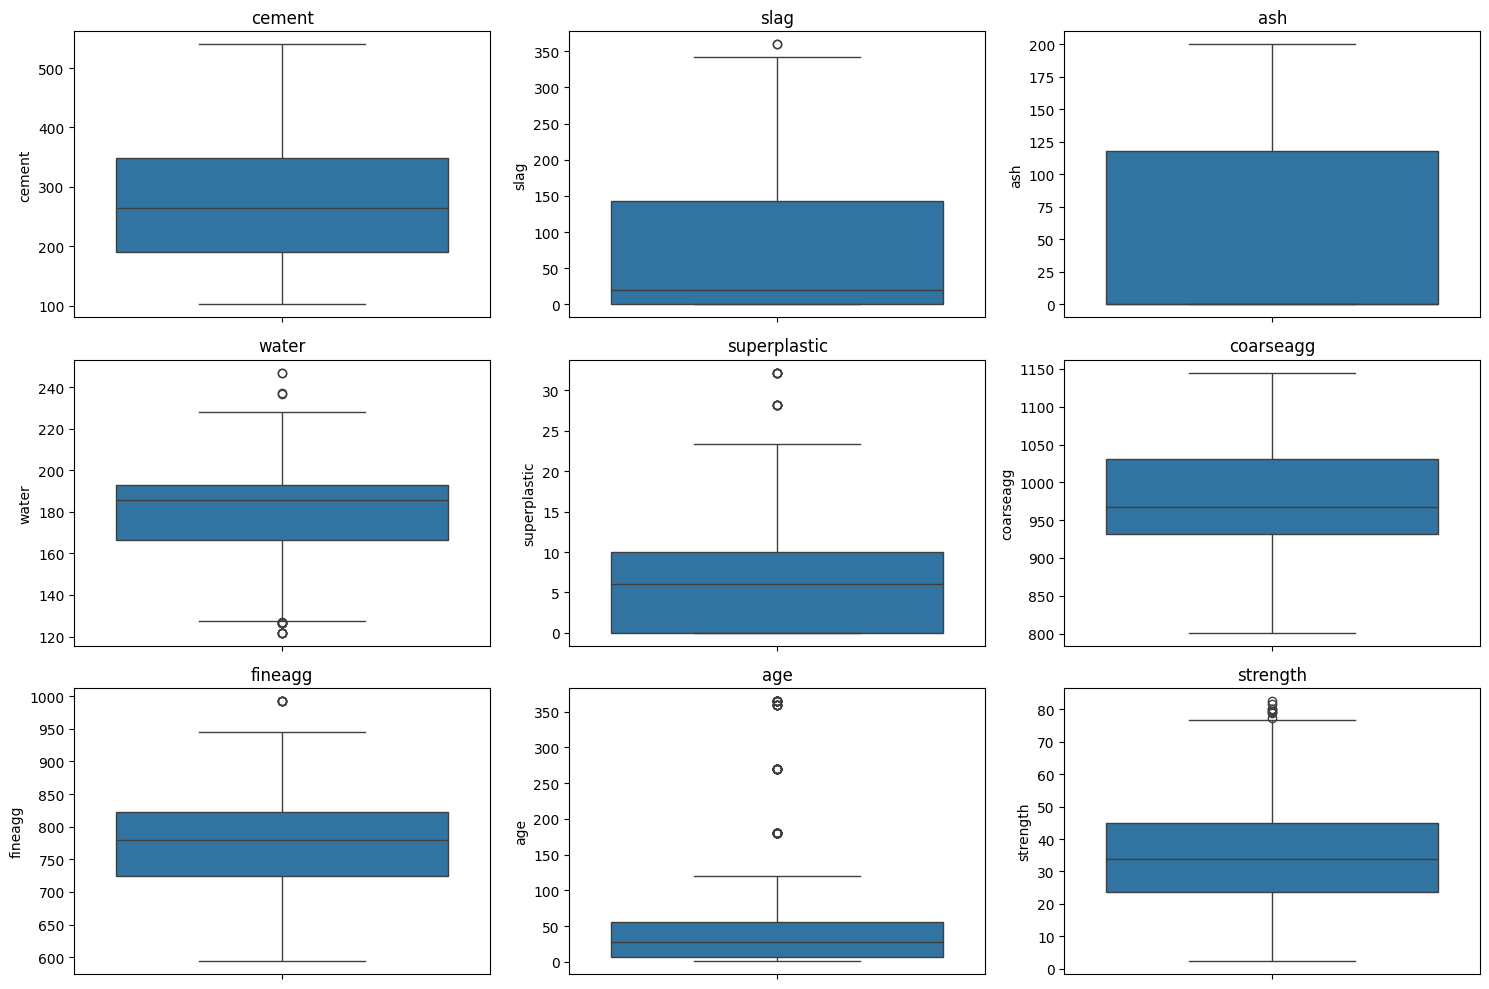

In [ ]:
# Initialize figure size for boxplots
plt.figure(figsize=(15, 10))

# Generate boxplots dynamically for each column to analyze feature dispersion
for i, col in enumerate(df.columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

# Optimize plot placements and show results
plt.tight_layout()
plt.show()

In [ ]:
# Detect and output the exact count of outlier values using the IQR method for each column
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, ":", len(outliers))

cement : 0
slag : 2
ash : 0
water : 15
superplastic : 10
coarseagg : 0
fineagg : 5
age : 59
strength : 8


## C. Bivariate Analysis – Scatter Plots

Scatter plots were created to understand relationships between individual input features and concrete strength.

Cement showed a generally positive relationship with concrete strength.

Age showed a generally positive relationship with strength.

The relationship between individual features and strength varied because concrete strength depends on multiple ingredients together.

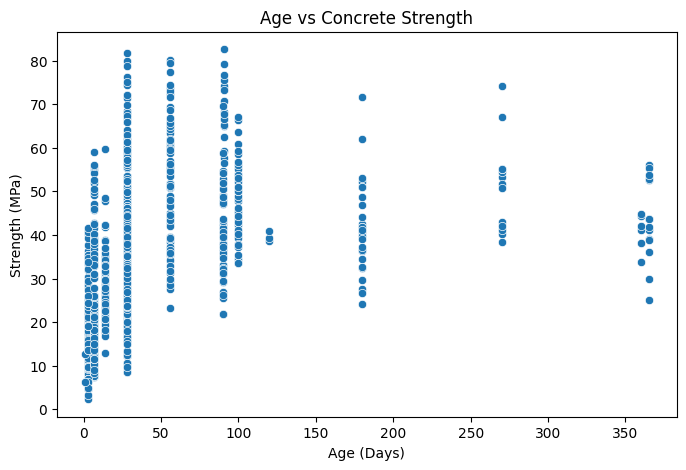

In [ ]:
# Plot concrete curing age against compressive strength using a scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='strength')

# Set title and axes labels
plt.title("Age vs Concrete Strength")
plt.xlabel("Age (Days)")
plt.ylabel("Strength (MPa)")
plt.show()

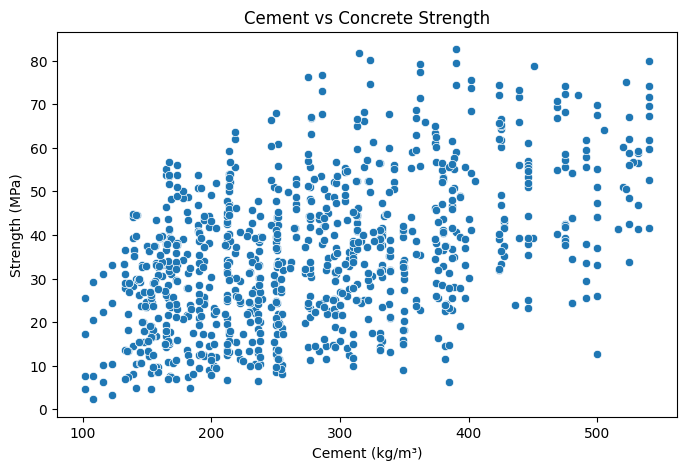

In [ ]:
# Plot cement raw volume against final concrete strength
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='cement', y='strength')

# Set plot labels
plt.title("Cement vs Concrete Strength")
plt.xlabel("Cement (kg/m³)")
plt.ylabel("Strength (MPa)")
plt.show()

## D. Correlation Analysis

A correlation matrix and heatmap were generated to understand the relationships among numerical variables.

Important observations:

Cement showed a positive correlation with concrete strength.

Superplasticizer and age also showed positive correlations.

Water showed a negative correlation with concrete strength.

Other ingredients showed weaker relationships individually.

In [ ]:
# Calculate pairwise correlation coefficients across all dataset variables
correlation = df.corr()

# Return the correlation matrix representation
correlation

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
cement,1.000000,-0.303324,-0.385610,-0.056625,0.060906,-0.086205,-0.245375,0.086348,0.488283
slag,-0.303324,1.000000,-0.312352,0.130262,0.019800,-0.277559,-0.289685,-0.042759,0.103374
ash,-0.385610,-0.312352,1.000000,-0.283314,0.414213,-0.026468,0.090262,-0.158940,-0.080648
water,-0.056625,0.130262,-0.283314,1.000000,-0.646946,-0.212480,-0.444915,0.279284,-0.269624
superplastic,0.060906,0.019800,0.414213,-0.646946,1.000000,-0.241721,0.207993,-0.194076,0.344209
coarseagg,-0.086205,-0.277559,-0.026468,-0.212480,-0.241721,1.000000,-0.162187,-0.005264,-0.144717
fineagg,-0.245375,-0.289685,0.090262,-0.444915,0.207993,-0.162187,1.000000,-0.156572,-0.186448
age,0.086348,-0.042759,-0.158940,0.279284,-0.194076,-0.005264,-0.156572,1.000000,0.337367
strength,0.488283,0.103374,-0.080648,-0.269624,0.344209,-0.144717,-0.186448,0.337367,1.000000


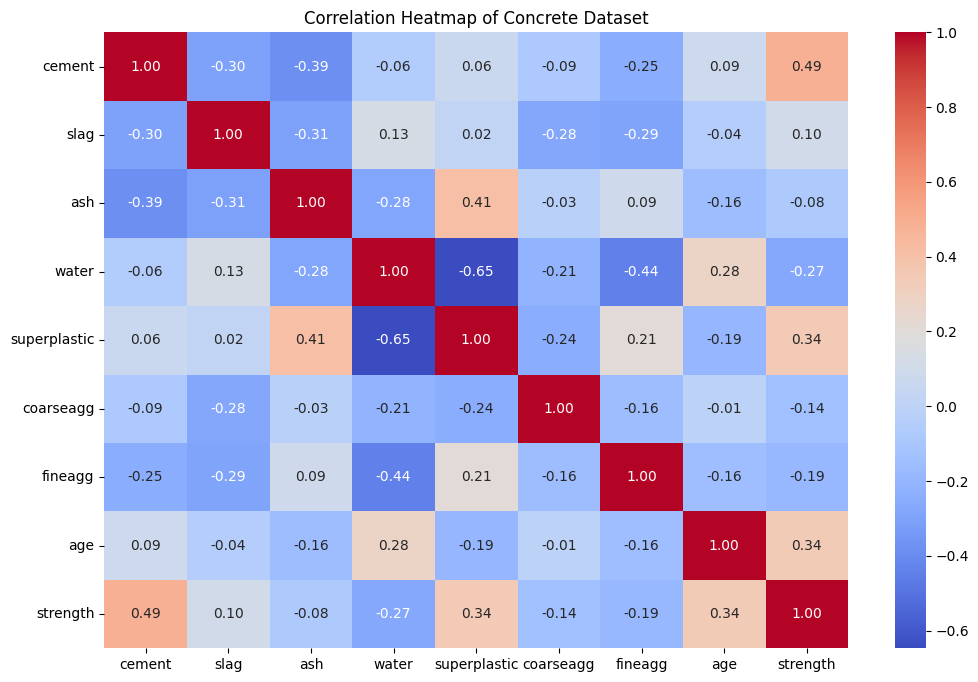

In [ ]:
# Set visual boundaries for the correlation heatmap
plt.figure(figsize=(12, 8))

# Render the heatmap with values, colors, and decimal precision formats
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Concrete Dataset")
plt.show()

## 6. Data Preprocessing

The dataset was separated into independent variables (X) and the dependent variable (y).

X contained the eight input features.

y contained the concrete compressive strength target variable.



In [ ]:
# Separate predictors from target: target variable is 'strength'
X = df.drop('strength', axis=1)
y = df['strength']

In [ ]:
# Display dimensional validation check for separated variables
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (1005, 8)
Target Variable Shape: (1005,)


## Train-Test split

The data was divided into training and testing sets to train the models and evaluate their prediction performance.

## Explanation:

80% of the data is used for training.

20% of the data is used for testing.

random_state=42 ensures reproducibility.


In [ ]:
# Split features and label targets into training and testing sets (80-20 split ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# Print shapes of train and test datasets to verify the split
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (804, 8)
X_test: (201, 8)
y_train: (804,)
y_test: (201,)


### Standard Scalar


StandardScaler was applied to the features for algorithms that are sensitive to feature scaling, especially KNN and Support Vector Regression.

The scaler was fitted only on training data and then used to transform the testing data to avoid data leakage.

In [ ]:
# Instantiate standard scaler scaling transformation utility
scaler = StandardScaler()

# Calculate mean & variance using training split features, then scale those features
X_train_scaled = scaler.fit_transform(X_train)

# Use training parameters to transform and scale test features without leakage
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Verify dimension structures of scaled feature arrays
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (804, 8)
Testing data shape: (201, 8)


## 7. Model Building

Seven regression algorithms were implemented to predict concrete compressive strength.

### 1. Linear Regression

Linear Regression is a supervised learning algorithm that predicts a continuous target variable by identifying a linear relationship between input features and the target.

In [ ]:
# Initialize a standard multilinear regression model
lr = LinearRegression()

# Train the model on the unscaled training split features and targets
lr.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Generate target predictions for test samples using linear regression
y_pred_lr = lr.predict(X_test)

In [ ]:
# Print prediction array output
y_pred_lr

array([23.46019162, 16.70304272, 22.45208992, 37.39624296, 42.88500822,
       22.1568172 , 14.60542252, 44.51712266, 33.29461637, 50.12870223,
       33.51852158, 29.09223858, 44.91076599, 50.72620597, 28.86931792,
       21.311598  , 32.82122051, 43.41014104, 37.38518333, 51.63672218,
       32.80717289, 14.33028425, 30.55628737, 29.75180646, 13.4061833 ,
       34.73404267, 46.86386689, 33.72787301, 30.55371311, 48.90588245,
       39.89833926, 46.24605265, 61.76724866, 38.01549768, 25.32709169,
       66.30266888, 37.83663606, 35.47400535, 35.97435845, 69.09500324,
       34.15320713, 28.83020125, 37.39873716, 39.45118386, 44.77210135,
       44.6110985 , 50.74480657, 23.68221608, 53.83507265, 32.79126741,
       32.29141421, 46.75815738, 29.24984248, 23.64573713, 21.31820652,
       31.47937995, 50.43614235, 21.89335165, 41.03445703, 58.25920648,
       31.11208627, 30.23521262, 29.7281413 , 30.75599676, 52.13640713,
       55.1197504 , 33.12653131, 31.70719496, 49.92244243, 58.70

In [ ]:
# Compute model metrics: MAE, MSE, RMSE, and R2 coefficients
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Display Linear Regression performance results
print("Linear Regression Results")
print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)

Linear Regression Results
MAE: 8.89525622146419
MSE: 125.2456480505019
RMSE: 11.191320210346136
R2 Score: 0.5801703029028777


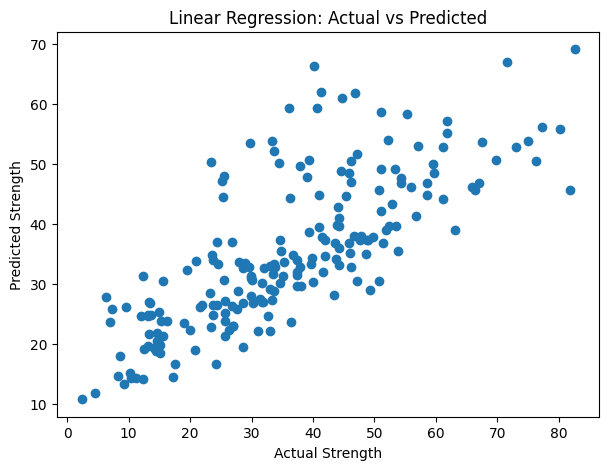

In [ ]:
# Configure actual versus predicted performance scatter plot for linear model
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_lr)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

### 2. Decision Tree Regressor

Decision Tree Regressor uses a tree-like structure to split data based on feature values and predict continuous numerical outputs.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Initialize non-linear Decision Tree Regressor model
dt_model = DecisionTreeRegressor(random_state=42)

# Train tree model using unscaled datasets
dt_model.fit(X_train, y_train)

# Predict final test metrics with tree model
y_pred_dt = dt_model.predict(X_test)

In [ ]:
# Compute individual Decision Tree regression scores
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Print metrics evaluation breakdown
print("Decision Tree Regressor Results")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Regressor Results
MAE: 3.775547263681592
MSE: 35.090811567164174
RMSE: 5.923749789378698
R2 Score: 0.8823738387684785


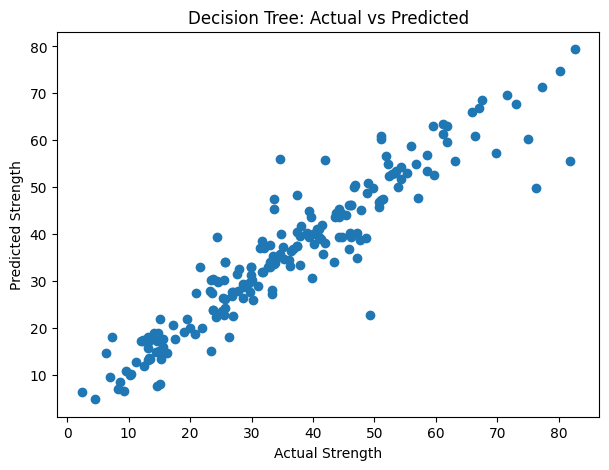

In [ ]:
# Render actual vs predicted plots for visual comparison of trees structure
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_dt)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Decision Tree: Actual vs Predicted")
plt.show()

### 3. Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines multiple decision trees and averages their predictions to improve accuracy and reduce overfitting.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Initialize an ensemble Random Forest regressor with 100 estimators
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train random forest ensemble model
rf_model.fit(X_train, y_train)

# Predict compressive strength of test set split
y_pred_rf = rf_model.predict(X_test)

In [ ]:
# Evaluate structural performance indicators of Random Forest model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display Random Forest model test result outcomes
print("Random Forest Regressor Results")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Regressor Results
MAE: 3.4978676036484253
MSE: 27.61734999419001
RMSE: 5.255221212678873
R2 Score: 0.9074252569797012


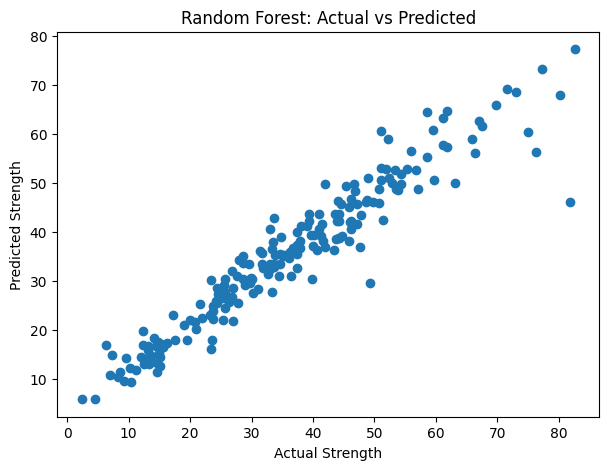

In [ ]:
# Generate comparative visual metrics via target scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

### 4. K-Nearest Neighbors Regressor (KNN)

KNN predicts the target value by identifying the nearest data points and calculating the average of their target values

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

# Set scaling structures for correct implementation of KNN model
scaler_knn = StandardScaler()
X_train_scaled = scaler_knn.fit_transform(X_train)
X_test_scaled = scaler_knn.transform(X_test)

# Instantiate KNN regression model with default 5 neighbors
knn_model = KNeighborsRegressor(n_neighbors=5)

# Fit the KNN model on scaled feature representations
knn_model.fit(X_train_scaled, y_train)

# Forecast strength predictions on the scaled testing segment
y_pred_knn = knn_model.predict(X_test_scaled)

In [ ]:
# Extract accuracy indicators on continuous KNN outcome variables
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Print metrics log output summary for neighbor algorithm
print("KNN Regressor Results")
print("MAE:", mae_knn)
print("MSE:", mse_knn)
print("RMSE:", rmse_knn)
print("R2 Score:", r2_knn)

KNN Regressor Results
MAE: 7.125303482587065
MSE: 84.49882561194029
RMSE: 9.19232427691388
R2 Score: 0.7167556963941847


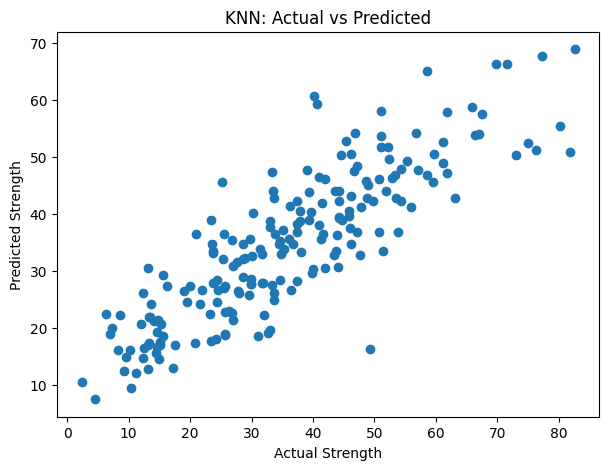

In [ ]:
# Map predictions against test properties for comparison plotting
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_knn)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("KNN: Actual vs Predicted")
plt.show()

### 5. Support Vector Regression (SVR)

SVR is a supervised learning algorithm that attempts to fit a function within an acceptable error margin while controlling model complexity.

In [ ]:
from sklearn.svm import SVR

# Initialize a Support Vector Regressor utilizing radial basis function kernels
svr_model = SVR(kernel='rbf')

# Fit SVR model on pre-scaled feature matrices
svr_model.fit(X_train_scaled, y_train)

# Evaluate predicted output targets using SVR models
y_pred_svr = svr_model.predict(X_test_scaled)

In [ ]:
# Retrieve exact metric scores of kernel models
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# Print results summary for validation models
print("Support Vector Regression Results")
print("MAE:", mae_svr)
print("MSE:", mse_svr)
print("RMSE:", rmse_svr)
print("R2 Score:", r2_svr)

Support Vector Regression Results
MAE: 8.34430876897251
MSE: 119.3094691607769
RMSE: 10.922887400352385
R2 Score: 0.6000686724189401


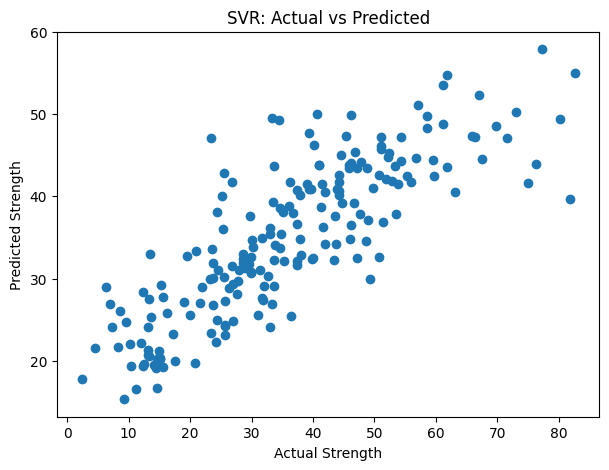

In [ ]:
# Render continuous predictions visualization
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_svr)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("SVR: Actual vs Predicted")
plt.show()

### 6. Gradient Boosting Regressor

Gradient Boosting builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Instantiate a sequential additive Gradient Boosting ensemble model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train gradient boosting model
gb_model.fit(X_train, y_train)

# Predict continuous compressive values using boosting trees
y_pred_gb = gb_model.predict(X_test)

In [ ]:
# Calculate boosting tree predictions error rates and variances
mae_gb = mean_absolute_error(y_test, y_pred_gb)
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

# Display testing accuracy log outputs
print("Gradient Boosting Regressor Results")
print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Regressor Results
MAE: 4.128914301303752
MSE: 31.403643872900282
RMSE: 5.603895419518487
R2 Score: 0.8947334099018797


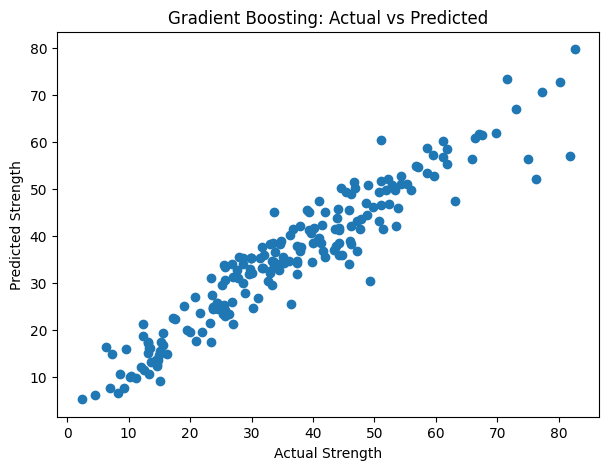

In [ ]:
# Plot exact comparison charts using regression scatter maps
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_gb)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.show()

### 7. XGBoost Regressor

XGBoost is an advanced gradient boosting algorithm that uses sequential decision trees and regularization techniques to improve prediction performance.

In [ ]:
# Import modern optimized gradient boosting algorithms framework
from xgboost import XGBRegressor

In [ ]:
# Initialize extreme gradient boosting (XGBoost) regression engine
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Fit extreme boosting structures onto our models
xgb_model.fit(X_train, y_train)

# Complete forecast using XGBoost systems
y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
# Gather metric evaluations over predictions outputs
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

# Print final extreme boosting results to evaluation console
print("XGBoost Regressor Results")
print("MAE:", mae_xgb)
print("MSE:", mse_xgb)
print("RMSE:", rmse_xgb)
print("R2 Score:", r2_xgb)

XGBoost Regressor Results
MAE: 4.138715964739595
MSE: 31.501309647711555
RMSE: 5.612602751639524
R2 Score: 0.8944060293238396


## 8. Model Evaluation

The models were evaluated and compared using four regression metrics.

Evaluation Metrics:

MAE (Mean Absolute Error): Measures the average absolute difference between actual and predicted values. Lower MAE indicates better performance.

MSE (Mean Squared Error): Measures the average squared prediction error. Lower MSE is better.

RMSE (Root Mean Squared Error): Measures prediction error in the same unit as the target variable (MPa). Lower RMSE is better.

R² Score: Measures how much variation in concrete compressive strength is explained by the model. A higher R² score indicates better performance.

In [ ]:
# Aggregate and construct a custom dataframe mapping metrics across all tested architectures
comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'SVR',
        'Gradient Boosting',
        'XGBoost'
    ],
    'MAE': [
        mae_lr, mae_dt, mae_rf, mae_knn,
        mae_svr, mae_gb, mae_xgb
    ],
    'MSE': [
        mse_lr, mse_dt, mse_rf, mse_knn,
        mse_svr, mse_gb, mse_xgb
    ],
    'RMSE': [
        rmse_lr, rmse_dt, rmse_rf, rmse_knn,
        rmse_svr, rmse_gb, rmse_xgb
    ],
    'R2 Score': [
        r2_lr, r2_dt, r2_rf, r2_knn,
        r2_svr, r2_gb, r2_xgb
    ]
})

# Output model comparison logs
comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,8.895256,125.245648,11.191320,0.580170
1,Decision Tree,3.775547,35.090812,5.923750,0.882374
2,Random Forest,3.497868,27.617350,5.255221,0.907425
3,KNN,7.125303,84.498826,9.192324,0.716756
4,SVR,8.344309,119.309469,10.922887,0.600069
5,Gradient Boosting,4.128914,31.403644,5.603895,0.894733
6,XGBoost,4.138716,31.501310,5.612603,0.894406


In [ ]:
# Sort summary logs to visually contrast accuracy in descending order
comparison.sort_values(
    by='R2 Score',
    ascending=False
)

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,3.497868,27.617350,5.255221,0.907425
5,Gradient Boosting,4.128914,31.403644,5.603895,0.894733
6,XGBoost,4.138716,31.501310,5.612603,0.894406
1,Decision Tree,3.775547,35.090812,5.923750,0.882374
3,KNN,7.125303,84.498826,9.192324,0.716756
4,SVR,8.344309,119.309469,10.922887,0.600069
0,Linear Regression,8.895256,125.245648,11.191320,0.580170


In [ ]:
# Dynamically select row mapping the highest R2 score metric on test set
best_model = comparison.loc[
    comparison['R2 Score'].idxmax()
]

# Print selected baseline champion name
print("Best Model:", best_model['Model'])
print("Best R2 Score:", best_model['R2 Score'])

Best Model: Random Forest
Best R2 Score: 0.9074252569797012


# Comparison Analysis:

Random Forest Regressor achieved the highest R² Score of approximately 90.74% and the lowest MAE, MSE, and RMSE among the seven evaluated models.

Decision Tree, Gradient Boosting, and XGBoost also showed good performance.

Linear Regression and SVR showed comparatively lower performance on this dataset.

Based on the comparison, Random Forest Regressor was selected for further optimization.

# 9. Hyperparameter Tuning Using GridSearchCV

Hyperparameter tuning was performed on the Random Forest Regressor to find suitable model settings and improve prediction performance.

GridSearchCV was used with 5-fold cross-validation to evaluate different combinations of hyperparameters.

The following parameters were explored:

n_estimators: Number of decision trees.

max_depth: Maximum depth of each tree.

min_samples_split: Minimum number of samples required to split an internal node.

min_samples_leaf: Minimum number of samples required at a leaf node.

The best estimator obtained through GridSearchCV was evaluated again using the testing dataset.

In [ ]:
# Import searching grid hyper-optimization wrappers
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

In [ ]:
# Configure hyperparameter exploration spaces mapping ensemble properties
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [ ]:
# Initialize basic random forest structures for tuning execution
rf = RandomForestRegressor(random_state=42)

# Set up parameter search pipeline incorporating five cross validations
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

# Execute grid search on training records
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='r2', verbose=1)

In [ ]:
# Display best parameters and validation scores found
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation R2:", grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross Validation R2: 0.8869654016978599


In [ ]:
# Extract and save our fully tuned candidate
best_rf_model = grid_search.best_estimator_

# Run tests utilizing newly optimized parameters
y_pred_tuned = best_rf_model.predict(X_test)

# Output metric outputs from optimized configuration
print("MAE:", mean_absolute_error(y_test, y_pred_tuned))
print("MSE:", mean_squared_error(y_test, y_pred_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_tuned)))
print("R2 Score:", r2_score(y_test, y_pred_tuned))

MAE: 3.532899735844591
MSE: 27.075073845061496
RMSE: 5.203371392190019
R2 Score: 0.9092429938430198


In [ ]:
# Print comparative variance scores demonstrating tuning effects
print("Before Tuning R2:", r2_rf)
print("After Tuning R2:", r2_score(y_test, y_pred_tuned))

Before Tuning R2: 0.9074252569797012
After Tuning R2: 0.9092429938430198


## Tuning Result Analysis:

After tuning, the R² Score increased from approximately 90.74% to 90.92%.

MSE and RMSE decreased slightly, while MAE increased slightly.

Overall, the tuned model showed a small improvement in performance based on R², MSE, and RMSE.

The tuned Random Forest Regressor was selected as the final model.

## 10. Model Saving Using Pickle

After selecting the tuned Random Forest model, it was saved using Python's Pickle module.

Pickle is used to serialize Python objects and store trained machine learning models in files.

The saved model can be loaded later and reused for predictions without training the model again.

The model was saved as:

concrete_strength_model.pkl

In [ ]:
import pickle

# Open output stream connection and serialize tuned champion model
with open('concrete_strength_model.pkl', 'wb') as file:
    pickle.dump(best_rf_model, file)

In [ ]:
# Deserialize saved models from disk back to live session contexts
with open('concrete_strength_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

In [ ]:
# Set up sample dataframe properties using hypothetical values
new_data = pd.DataFrame({
    'cement': [350],
    'slag': [100],
    'ash': [0],
    'water': [180],
    'superplastic': [8],
    'coarseagg': [1000],
    'fineagg': [700],
    'age': [28]
})

## 11. Prediction on New Data

The saved model was loaded and tested using a new concrete sample.

The new sample included the following input features:

Cement: 350

Slag: 100

Ash: 0

Water: 180

Superplasticizer: 8

Coarse Aggregate: 1000

Fine Aggregate: 700

Age: 28 days

The loaded Random Forest model generated a predicted concrete compressive strength value in MPa.

This demonstrated that the saved model could be reused to predict concrete strength for new input samples without retraining.

In [ ]:
# Run custom user scenarios against our deserialized model object
prediction = loaded_model.predict(new_data)

# Display target prediction values
print("Predicted Concrete Compressive Strength:", prediction[0], "MPa")

Predicted Concrete Compressive Strength: 49.82300000000002 MPa


# 12. Model Comparison Report – Concrete Compressive Strength Prediction
1. Introduction
The objective of this project is to compare different machine learning regression algorithms and identify the best-performing model for predicting concrete compressive strength.

The models were trained using the concrete ingredients and age as input features. Their performance was evaluated using four metrics:
- MAE (Mean Absolute Error): Measures the average absolute difference between actual and predicted values. Lower is better.
- MSE (Mean Squared Error): Measures the average squared prediction error and penalizes larger errors. Lower is better.
- RMSE (Root Mean Squared Error): Square root of MSE, expressed in the original strength unit (MPa). Lower is better.
- R² Score: Measures how much variation in concrete strength is explained by the model. Higher is better.

2. Model Analysis
1. Linear Regression
- Achieved an R² score of 0.5802.
- It provides a basic linear relationship between concrete ingredients and strength.
- Its performance was limited because concrete strength depends on complex, nonlinear relationships.
2. Decision Tree Regressor
- Achieved an R² score of 0.8824.
- It performed better than Linear Regression.
- It can capture nonlinear relationships between input features and concrete strength.
3. Random Forest Regressor
- Achieved an R² score of 0.9074.
- It produced the lowest MAE and RMSE among the initial models.
- It combines multiple decision trees to improve prediction performance and reduce overfitting compared with a single tree.
4. KNN Regressor
- Achieved an R² score of 0.7168.
- It predicts strength based on similar data points.
- Feature scaling was applied because KNN is distance-based.
5. Support Vector Regressor (SVR)
- Achieved an R² score of 0.6001.
- It attempts to find a function that predicts values within an acceptable error margin.
- StandardScaler was applied because SVR is sensitive to feature scales.
6. Gradient Boosting Regressor
- Achieved an R² score of 0.8947.
- It builds models sequentially, with each new model attempting to correct errors made by previous models.
- It provided strong prediction performance.
7. XGBoost Regressor
- Achieved an R² score of 0.8944.
- It uses an optimized gradient boosting approach.
- It also provided good prediction performance, although it was slightly below Random Forest.
4. Hyperparameter Tuning – Random Forest
Random Forest achieved the best initial performance, so GridSearchCV was applied to improve its performance.

The following parameters were tested:
- n_estimators: Number of decision trees.
- max_depth: Maximum depth of each tree.
- min_samples_split: Minimum samples required to split a node.
- min_samples_leaf: Minimum samples required at a leaf node.
After hyperparameter tuning, the model achieved:
Metric	Before Tuning	After Tuning
MAE	3.4979	3.5329
MSE	27.6174	27.0751
RMSE	5.2552	5.2034
R² Score	0.9074	0.9092

The tuned model improved its MSE, RMSE and R² score slightly. MAE increased slightly, so not every metric improved.
5. Best Model Selection
Selected model: Tuned Random Forest Regressor
The tuned Random Forest Regressor was selected as the best model because:
- It achieved the highest R² score of 0.9092.
- It achieved a low RMSE of 5.2034 MPa.
- It had a low MSE of 27.0751.
- It performed better overall than the other evaluated models based on the comparison.

## The final selected model: Tuned random forest regressor

# 13. Challenges Faced and Solutions

1. Duplicate Records

Challenge: The dataset contained duplicate observations.

Solution: Identified and removed 25 duplicate records using Pandas.

2. Missing Values

Challenge: Checking data completeness.

Solution: Used missing-value analysis and confirmed that no missing values were present.

3. Outlier Detection

Challenge: Some numerical features contained extreme values.

Solution: Used boxplots and the IQR method to identify potential outliers. Retained them because they could represent valid concrete measurements.

4. Feature Scaling

Challenge: KNN and SVR are sensitive to different feature scales.

Solution: Applied StandardScaler to training and testing features, fitting the scaler only on training data.

5. Model Selection

Challenge: Identifying the most suitable regression algorithm.

Solution: Implemented and compared seven regression models using MAE, MSE, RMSE, and R² Score.

6. Model Optimization

Challenge: Improving the performance of the selected Random Forest model.

Solution: Used GridSearchCV with 5-fold cross-validation to search for suitable hyperparameter combinations.

7. Model Reusability

Challenge: Reusing the trained model for future predictions.

Solution: Saved and loaded the tuned Random Forest model using Pickle.

# 14. Final Project Conclusion

The Concrete Compressive Strength Prediction project demonstrated the application of supervised machine learning regression algorithms to predict concrete strength based on its ingredient quantities and curing age.

Complete data understanding, data cleaning, exploratory data analysis, outlier detection, correlation analysis, preprocessing, model development, and model evaluation were performed.

Seven regression algorithms were implemented and compared using MAE, MSE, RMSE, and R² Score.

Among the evaluated models, Random Forest Regressor achieved the best initial performance with an R² Score of approximately 90.74%.

After hyperparameter tuning using GridSearchCV, the tuned Random Forest model achieved an R² Score of approximately 90.92% and an RMSE of approximately 5.20 MPa.

The tuned Random Forest model was saved using Pickle and tested with a new concrete sample to demonstrate its prediction capability.

Final Outcome: The tuned Random Forest Regressor was selected as the best-performing model among the seven evaluated algorithms for predicting concrete compressive strength.

This project demonstrates how machine learning can be applied to estimate concrete strength and understand the influence of different ingredients and curing age on concrete performance.